# Credit Card Fraud Detection Analysis

Business question: which transaction patterns signal fraud, and which triggers should a real-time alert system use?

Data: simulated card transactions from Kaggle (Sparkov), Jan 2019 to Dec 2020. Tools: pandas, matplotlib, Power BI.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.4f}".format)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

NIGHT = [22, 23, 0, 1, 2, 3]

## Loading the data

In [2]:
train = pd.read_csv("C:/Users/winkle/Downloads/fraudTrain.csv")
test = pd.read_csv("C:/Users/winkle/Downloads/fraudTest.csv")
train["split"] = "train"
test["split"] = "test"
df = pd.concat([train, test], ignore_index=True)

print(df.shape)
print(df.isna().sum().sum(), "nulls,", df.duplicated().sum(), "duplicates")
print(df["trans_date_trans_time"].min(), "to", df["trans_date_trans_time"].max())
print(df[["cc_num", "merchant", "state"]].nunique())
print(df["is_fraud"].value_counts(normalize=True))

(1852394, 24)
0 nulls, 0 duplicates
2019-01-01 00:00:18 to 2020-12-31 23:59:34
cc_num      999
merchant    693
state        51
dtype: int64
is_fraud
0   0.9948
1   0.0052
Name: proportion, dtype: float64


## Cleaning

In [3]:
df = df.drop(columns=["Unnamed: 0", "first", "last", "street"])
df["trans_dt"] = pd.to_datetime(df["trans_date_trans_time"])
df["dob"] = pd.to_datetime(df["dob"])

df["month"] = df["trans_dt"].dt.month
df["year"] = df["trans_dt"].dt.year
df["hour"] = df["trans_dt"].dt.hour
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
df["dow"] = pd.Categorical(df["trans_dt"].dt.day_name(), categories=order, ordered=True)
df["age"] = ((df["trans_dt"] - df["dob"]).dt.days // 365.25).astype(int)
df["night"] = df["hour"].isin(NIGHT)

# haversine distance, home to merchant (km)
p1, p2 = np.radians(df["lat"]), np.radians(df["merch_lat"])
a = np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(np.radians(df["merch_long"] - df["long"]) / 2) ** 2
df["dist_km"] = 2 * 6371 * np.arcsin(np.sqrt(a))

bins = [0, 50, 100, 150, 200, 250, 300, 400, 500, 750, 1000, 2000, 5000, np.inf]
df["amt_band"] = pd.cut(df["amt"], bins=bins)

base = df["is_fraud"].mean()
print(f"fraud rate {base:.3%}")
df[["amt", "age", "dist_km"]].describe()

fraud rate 0.521%


,amt,age,dist_km
count,"1,852,394.0000","1,852,394.0000","1,852,394.0000"
mean,70.0636,45.7639,76.1117
std,159.2540,17.4124,29.1170
min,1.0000,13.0000,0.0223
25%,9.6400,32.0000,55.3201
50%,47.4500,44.0000,78.2164
75%,83.1000,57.0000,98.5095
max,"28,948.9000",96.0000,152.1172


## Time patterns

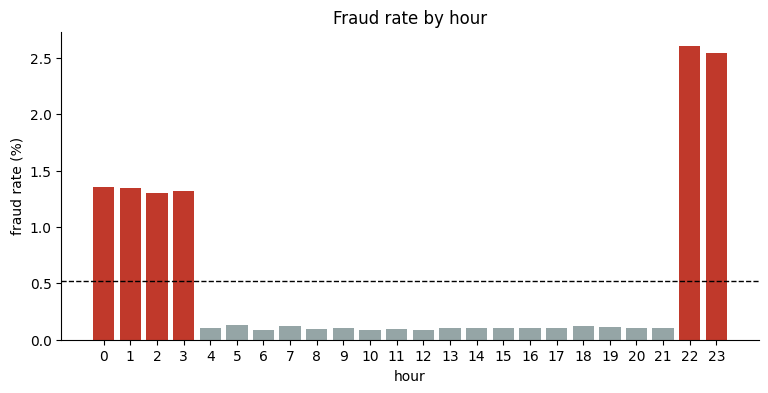

night: 23.5% of transactions, 84.6% of fraud


In [4]:
def rate(by, min_n=1000):
    t = df.groupby(by, observed=True)["is_fraud"].agg(txns="count", frauds="sum", fraud_rate="mean")
    t["lift"] = t["fraud_rate"] / base
    return t[t["txns"] >= min_n]

h = rate("hour")
colors = ["#c0392b" if x in NIGHT else "#95a5a6" for x in h.index]
plt.figure(figsize=(9, 4))
plt.bar(h.index, h["fraud_rate"] * 100, color=colors)
plt.axhline(base * 100, color="black", ls="--", lw=1)
plt.title("Fraud rate by hour")
plt.xlabel("hour")
plt.ylabel("fraud rate (%)")
plt.xticks(range(24))
plt.show()

n = df["night"]
print(f"night: {n.mean():.1%} of transactions, {df.loc[n, 'is_fraud'].sum() / df['is_fraud'].sum():.1%} of fraud")

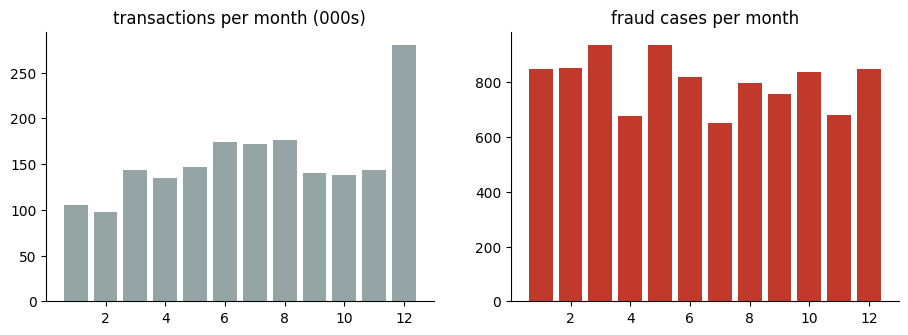

        txns  frauds  fraud_rate   lift
year                                   
2019  924850    5220      0.0056 1.0833
2020  927544    4431      0.0048 0.9169
             txns  frauds  fraud_rate   lift
dow                                         
Monday     369418    1484      0.0040 0.7710
Tuesday    270340    1266      0.0047 0.8988
Wednesday  183913    1125      0.0061 1.1741
Thursday   206741    1317      0.0064 1.2227
Friday     215078    1376      0.0064 1.2280
Saturday   263227    1493      0.0057 1.0887
Sunday     343677    1590      0.0046 0.8880


In [5]:
m = df.groupby("month")["is_fraud"].agg(["size", "sum"])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].bar(m.index, m["size"] / 1000, color="#95a5a6")
ax[0].set_title("transactions per month (000s)")
ax[1].bar(m.index, m["sum"], color="#c0392b")
ax[1].set_title("fraud cases per month")
plt.show()

print(rate("year", 0))
print(rate("dow", 0))

Fraud counts stay flat while volume changes, so month and weekday rate differences are volume effects, and the strong time signal is the hour of day.

## Amount

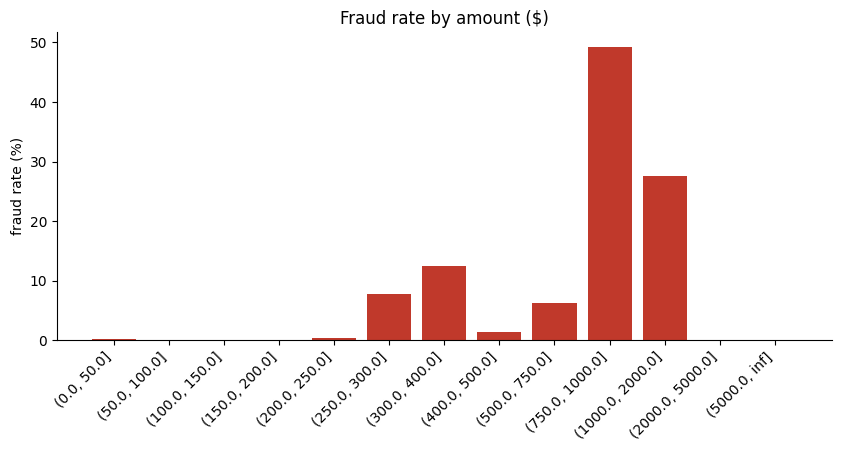

$200+: 4.7% of transactions, 75.8% of fraud


,txns,frauds,fraud_rate,lift
amt_band,,,,
"(0.0, 50.0]",961229,2069,0.0022,0.4131
"(50.0, 100.0]",556287,63,0.0001,0.0217
"(100.0, 150.0]",182689,196,0.0011,0.2059
"(150.0, 200.0]",64916,8,0.0001,0.0237
"(200.0, 250.0]",33352,123,0.0037,0.7079
"(250.0, 300.0]",11477,885,0.0771,14.8005
"(300.0, 400.0]",12075,1499,0.1241,23.8273
"(400.0, 500.0]",8660,124,0.0143,2.7483
"(500.0, 750.0]",10512,663,0.0631,12.1057


In [6]:
a = rate("amt_band", 0)
plt.figure(figsize=(10, 4))
plt.bar(range(len(a)), a["fraud_rate"] * 100, color="#c0392b")
plt.xticks(range(len(a)), [str(i) for i in a.index], rotation=45, ha="right")
plt.title("Fraud rate by amount ($)")
plt.ylabel("fraud rate (%)")
plt.show()

big = df["amt"] >= 200
print(f"$200+: {big.mean():.1%} of transactions, {df.loc[big, 'is_fraud'].sum() / df['is_fraud'].sum():.1%} of fraud")
a

Where the rate first jumps, that it is uneven and not smooth, that nothing above 2,000 dollars is fraud, and 200+ dollars transactions hold 75.8% of fraud.

## Category

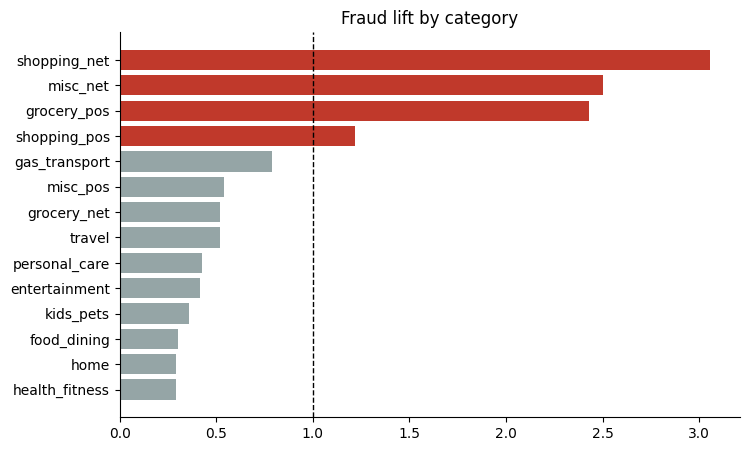

In [7]:
c = rate("category").sort_values("lift")
plt.figure(figsize=(8, 5))
plt.barh(c.index, c["lift"], color=["#c0392b" if x > 1 else "#95a5a6" for x in c["lift"]])
plt.axvline(1, color="black", ls="--", lw=1)
plt.title("Fraud lift by category")
plt.show()

In [8]:
big = df[df["amt"] >= 250]
big.groupby("category")["is_fraud"].agg(txns="size", frauds="sum", fraud_rate="mean").sort_values("fraud_rate", ascending=False)

,txns,frauds,fraud_rate
category,,,
grocery_pos,2498,2221,0.8891
shopping_net,11281,2219,0.1967
misc_net,7365,1182,0.1605
home,1187,141,0.1188
entertainment,2836,292,0.1030
shopping_pos,10988,1056,0.0961
misc_pos,6915,81,0.0117
food_dining,780,0,0.0000
health_fitness,749,0,0.0000


In [23]:
# small-amount fraud: which categories?
df[(df["is_fraud"] == 1) & (df["amt"] <= 100)].groupby("category").size().sort_values(ascending=False)

# category-aware rules
large_cats = ["grocery_pos", "shopping_net", "misc_net", "home", "entertainment", "shopping_pos"]
rules2 = {
    "amt >= 250": lambda d: d["amt"] >= 250,
    "amt >= 250 AND large_cats": lambda d: (d["amt"] >= 250) & d["category"].isin(large_cats),
    "grocery_pos AND amt >= 250": lambda d: (d["amt"] >= 250) & (d["category"] == "grocery_pos"),
}
rows = []

In [28]:
for name, f in rules2.items():
    for s_, part in df.groupby("split"):
        rows.append({"rule": name, "split": s_, **evaluate(part, f(part)).to_dict()})
rows = []
for name, f in rules2.items():
    for s_, part in df.groupby("split"):
        rows.append({"rule": name, "split": s_, **evaluate(part, f(part)).to_dict()})
rule2_results = pd.DataFrame(rows)
rule2_results.pivot(index="rule", columns="split").round(3)

alerts_per_day         precision        recall  \
split                                test   train      test  train   test   
rule                                                                        
amt >= 250                        79.7110 71.4850    0.1020 0.1460 0.7380   
amt >= 250 AND large_cats         52.4120 48.3030    0.1540 0.2130 0.7300   
grocery_pos AND amt >= 250         2.9590  3.5760    0.8400 0.9040 0.2250   

                                  dollar_recall         
split                       train          test  train  
rule                                                    
amt >= 250                 0.7470        0.9810 0.9830  
amt >= 250 AND large_cats  0.7390        0.9690 0.9700  
grocery_pos AND amt >= 250 0.2320        0.1330 0.1360

In [29]:
tr_big = tr[tr["amt"] >= 250].groupby("category")["is_fraud"].agg(txns="size", frauds="sum", fraud_rate="mean")
print(tr_big.sort_values("fraud_rate", ascending=False))

                txns  frauds  fraud_rate
category                                
grocery_pos     1924    1739      0.9038
shopping_net    8068    1713      0.2123
misc_net        5201     915      0.1759
home             872     103      0.1181
entertainment   2036     233      0.1144
shopping_pos    7886     843      0.1069
misc_pos        4868      64      0.0131
food_dining      542       0      0.0000
health_fitness   535       0      0.0000
kids_pets        690       0      0.0000
personal_care    584       0      0.0000
travel          5253       0      0.0000


## Distance

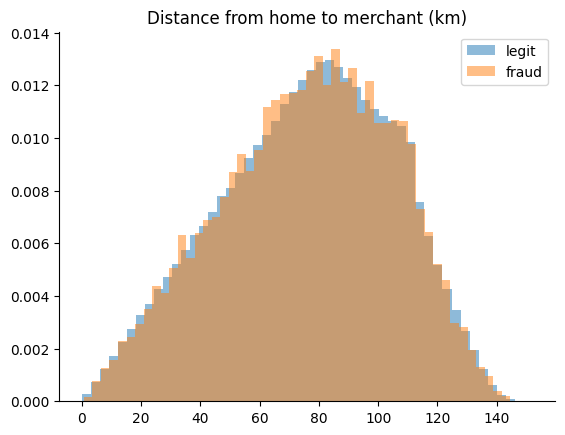

,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
0,"1,842,743.0000",76.1110,29.1183,0.0223,55.3187,78.2167,98.5102,152.1172
1,"9,651.0000",76.2562,28.8655,0.7388,55.5731,78.1019,98.4183,144.5224


In [13]:
for flag, label in [(0, "legit"), (1, "fraud")]:
    plt.hist(df.loc[df["is_fraud"] == flag, "dist_km"], bins=50, density=True, alpha=0.5, label=label)
plt.legend()
plt.title("Distance from home to merchant (km)")
plt.show()

df.groupby("is_fraud")["dist_km"].describe()

## Geography

21 of 51 states have 20+ cards


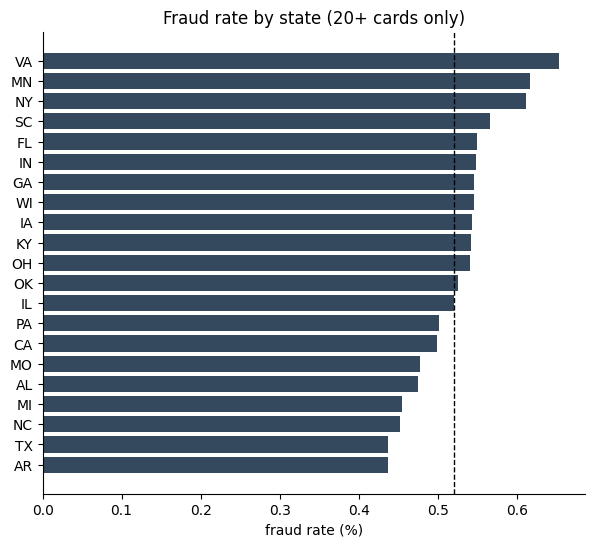

In [14]:
cards = df.groupby("state")["cc_num"].nunique()
ok = cards[cards >= 20].index
print(len(ok), "of", len(cards), "states have 20+ cards")

s = df[df["state"].isin(ok)].groupby("state")["is_fraud"].agg(txns="size", frauds="sum", fraud_rate="mean")
s["cards"] = cards
s = s.sort_values("fraud_rate")

plt.figure(figsize=(7, 6))
plt.barh(s.index, s["fraud_rate"] * 100, color="#34495e")
plt.axvline(base * 100, color="black", ls="--", lw=1)
plt.title("Fraud rate by state (20+ cards only)")
plt.xlabel("fraud rate (%)")
plt.show()

In [15]:
per_card = df[df["is_fraud"] == 1].groupby("cc_num").size().sort_values(ascending=False)
top = per_card.head(int(len(per_card) * 0.1)).sum() / per_card.sum()
print(len(per_card), "of", df["cc_num"].nunique(), "cards have at least one fraud")
print(f"top 10% of those cards account for {top:.1%} of fraud")

976 of 999 cards have at least one fraud
top 10% of those cards account for 15.2% of fraud


Only 21 of 51 states have 20+ cards. Their rates range from 0.44% to 0.65%, too small a gap with so few cardholders to call any state riskier. Fraud is spread across cards, not concentrated in a few.

## Night and amount together

In [16]:
df["amt_group"] = pd.cut(df["amt"], [0, 50, 200, np.inf], labels=["<=50", "50-200", ">200"])
j = df.groupby(["night", "amt_group"], observed=True)["is_fraud"].agg(txns="size", frauds="sum", fraud_rate="mean")
j["share_of_fraud"] = j["frauds"] / j["frauds"].sum()
j

txns  frauds  fraud_rate  share_of_fraud
night amt_group                                            
False <=50       753187     326      0.0004          0.0338
      50-200     602035      46      0.0001          0.0048
      >200        62151    1110      0.0179          0.1150
True  <=50       208042    1743      0.0084          0.1806
      50-200     201857     221      0.0011          0.0229
      >200        25122    6205      0.2470          0.6429

Night transactions over 200 dollars are 1.4% of volume but hold 64% of fraud. Small night transactions hold 18% and daytime large ones 11.5%, so no single rule covers everything.

## Alert rules

In [17]:
def evaluate(d, mask):
    fraud = d["is_fraud"] == 1
    days = (d["trans_dt"].max() - d["trans_dt"].min()).days + 1
    return pd.Series({
        "alerts_per_day": mask.sum() / days,
        "precision": (mask & fraud).sum() / mask.sum(),
        "recall": (mask & fraud).sum() / fraud.sum(),
        "dollar_recall": d.loc[mask & fraud, "amt"].sum() / d.loc[fraud, "amt"].sum(),
    })

risky = ["shopping_net", "misc_net", "grocery_pos"]
rules = {
    "amt >= 200": lambda d: d["amt"] >= 200,
    "amt >= 500": lambda d: d["amt"] >= 500,
    "night": lambda d: d["night"],
    "night AND amt >= 200": lambda d: d["night"] & (d["amt"] >= 200),
    "night OR amt >= 200": lambda d: d["night"] | (d["amt"] >= 200),
    "risky category AND amt >= 200": lambda d: d["category"].isin(risky) & (d["amt"] >= 200),
}

rows = []
for name, f in rules.items():
    for s_, part in df.groupby("split"):
        rows.append({"rule": name, "split": s_, **evaluate(part, f(part)).to_dict()})
rule_results = pd.DataFrame(rows)
rule_results.pivot(index="rule", columns="split").round(3)

alerts_per_day          precision        recall  \
split                                   test    train      test  train   test   
rule                                                                            
amt >= 200                          130.6860 115.1120    0.0640 0.0920 0.7510   
amt >= 500                           31.3300  29.0540    0.1700 0.2330 0.4830   
night                               670.8200 566.6950    0.0140 0.0210 0.8420   
night AND amt >= 200                 36.2630  33.6250    0.1940 0.2680 0.6350   
night OR amt >= 200                 765.2420 648.1820    0.0140 0.0210 0.9580   
risky category AND amt >= 200        57.7320  51.7570    0.1120 0.1570 0.5860   

                                     dollar_recall         
split                          train          test  train  
rule                                                       
amt >= 200                    0.7600        0.9870 0.9890  
amt >= 500                    0.4860        0.8280 0.8260  
night                         0.8480        0.8470 0.8440  
night AND amt >= 200          0.6450        0.8360 0.8350  
night OR amt >= 200           0.9620        0.9980 0.9980  
risky category AND amt >= 200 0.5820        0.7670 0.7480

Night alone fires about 670 alerts a day at 1.4% precision, which is unusable. Night AND amount of 200+ fires 36 a day at 19% precision and catches 64% of fraud. Adding category raised precision further.

### Choosing the threshold

In [18]:
tr = df[df["split"] == "train"]
te = df[df["split"] == "test"]

rows = []
for t in [150, 200, 250, 300, 400, 500, 750, 1000]:
    for s_, part in [("train", tr), ("test", te)]:
        m = part["amt"] >= t
        for r, mask in [("amt", m), ("night AND amt", m & part["night"])]:
            rows.append({"rule": r, "threshold": t, "split": s_, **evaluate(part, mask).to_dict()})
sweep = pd.DataFrame(rows)

sweep.pivot_table(index=["rule", "threshold"], columns="split",
                  values=["alerts_per_day", "precision", "recall", "dollar_recall"]).round(3)

alerts_per_day          dollar_recall         \
split                             test    train          test  train   
rule          threshold                                                
amt           150             231.8610 199.2900        0.9870 0.9890   
              200             130.6860 115.1120        0.9870 0.9890   
              250              79.7110  71.4850        0.9810 0.9830   
              300              62.6190  56.3180        0.9350 0.9330   
              400              44.6960  40.3330        0.8370 0.8380   
              500              31.3300  29.0540        0.8280 0.8260   
              750              15.3760  15.2680        0.7390 0.7390   
              1000              8.1600   7.3180        0.2620 0.2580   
night AND amt 150              60.5260  54.2450        0.8360 0.8350   
              200              36.2630  33.6250        0.8360 0.8350   
              250              22.9850  22.4410        0.8320 0.8300   
              300              18.5570  18.2080        0.7960 0.7860   
              400              13.1550  13.0990        0.7090 0.7050   
              500              10.2470  10.5840        0.7020 0.6950   
              750               6.3040   7.0200        0.6210 0.6200   
              1000              2.5980   2.6820        0.2240 0.2150   

                        precision        recall         
split                        test  train   test  train  
rule          threshold                                 
amt           150          0.0360 0.0530 0.7520 0.7610  
              200          0.0640 0.0920 0.7510 0.7600  
              250          0.1020 0.1460 0.7380 0.7470  
              300          0.1150 0.1620 0.6520 0.6540  
              400          0.1220 0.1730 0.4940 0.4990  
              500          0.1700 0.2330 0.4830 0.4860  
              750          0.2970 0.3820 0.4130 0.4180  
              1000         0.1740 0.2410 0.1290 0.1270  
night AND amt 150          0.1160 0.1660 0.6360 0.6460  
              200          0.1940 0.2680 0.6350 0.6450  
              250          0.3010 0.3940 0.6260 0.6340  
              300          0.3330 0.4230 0.5590 0.5520  
              400          0.3530 0.4480 0.4200 0.4200  
              500          0.4430 0.5390 0.4110 0.4090  
              750          0.6090 0.6960 0.3470 0.3500  
              1000         0.4660 0.5500 0.1100 0.1060

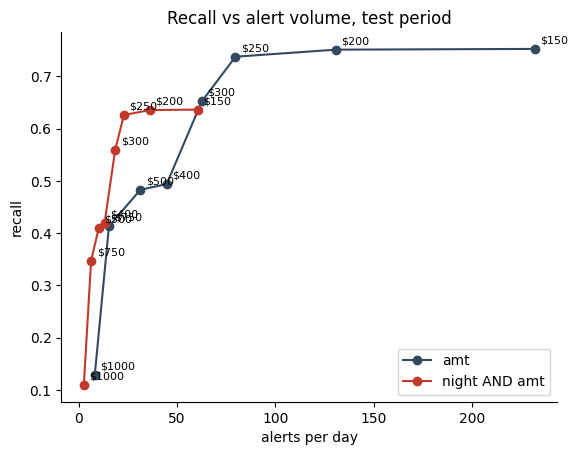

In [19]:
for r, col in [("amt", "#34495e"), ("night AND amt", "#c0392b")]:
    x = sweep[(sweep["rule"] == r) & (sweep["split"] == "test")]
    plt.plot(x["alerts_per_day"], x["recall"], marker="o", label=r, color=col)
    for _, row in x.iterrows():
        plt.annotate(f"${int(row['threshold'])}", (row["alerts_per_day"], row["recall"]), xytext=(4, 4), textcoords="offset points", fontsize=8)
plt.xlabel("alerts per day")
plt.ylabel("recall")
plt.title("Recall vs alert volume, test period")
plt.legend()
plt.show()

### Two tiers

In [20]:
rows = []
for T in [200, 250]:
    for s_, part in [("train", tr), ("test", te)]:
        big = part["amt"] >= T
        t1 = part["night"] & big
        t2 = ~part["night"] & big
        for label, mask in [("tier 1 (night)", t1), ("tier 2 (day)", t2), ("both", t1 | t2)]:
            rows.append({"threshold": T, "tier": label, "split": s_, **evaluate(part, mask).to_dict()})
tiers = pd.DataFrame(rows)
tiers.round(3)

,threshold,tier,split,alerts_per_day,precision,recall,dollar_recall
0,200,tier 1 (night),train,33.6250,0.2680,0.6450,0.8350
1,200,tier 2 (day),train,81.4870,0.0200,0.1150,0.1540
2,200,both,train,115.1120,0.0920,0.7600,0.9890
3,200,tier 1 (night),test,36.2630,0.1940,0.6350,0.8360
4,200,tier 2 (day),test,94.4230,0.0140,0.1160,0.1510
5,200,both,test,130.6860,0.0640,0.7510,0.9870
6,250,tier 1 (night),train,22.4410,0.3940,0.6340,0.8300
7,250,tier 2 (day),train,49.0450,0.0320,0.1130,0.1530
8,250,both,train,71.4850,0.1460,0.7470,0.9830
9,250,tier 1 (night),test,22.9850,0.3010,0.6260,0.8320


In [21]:
# any fraud above $2,000 in the test period?
te.loc[te["amt"] > 2000, "is_fraud"].agg(["count", "sum"])

count    359
sum        0
Name: is_fraud, dtype: int64

## Recommendations

1. Primary trigger: night (10 PM to 4 AM) AND amount of 250 dollars or more. About 23 alerts a day, 30% precision, catches 63% of fraud cases and 83% of fraud dollars. Send these to immediate review or step-up verification.

2. Auto-hold candidate: grocery_pos AND amount of 250 dollars or more. About 3 alerts a day with 84% precision, but it catches only 23% of fraud, so it supplements the primary trigger.

3. Optional second tier: daytime transactions of 250 dollars or more. Adds about 57 alerts a day at 2% precision, and raises recall from 63% to 74% and dollar recall from 83% to 98%. Only worth it if the review team has the capacity.

4. Not recommended: night alone (about 670 alerts a day, 1.4% precision), night OR amount (765 a day), distance from home, state, month and weekday. They either flood the queue or showed no real signal.

5. Gap: small night transactions (50 dollars or less) hold about 18% of fraud and no amount rule catches them. Catching them would need card-level behaviour, such as repeated small purchases, which this analysis does not cover.

Thresholds are based on a simulated dataset, so treat them as examples. The method of testing rules on train and test, and comparing alert volume with recall, is what carries over to real data.

## Limitations


- The data is simulated (Sparkov), so the sharp patterns, such as fraud jumping at 10 PM and almost vanishing at 4 AM, were most likely built into the generator. The exact thresholds will not carry over to real data. The method will.
- Only 999 cards, so state comparisons are weak. I left out 30 of 51 states for having fewer than 20 cards, and the rest show no real difference.
- Month and weekday differences follow transaction volume, since fraud counts are flat, so I make no seasonal claim.
- Distance from home did not separate fraud from legit (median about 78 km for both), and every transaction is within about 150 km of home, so it was not tested as a long-distance signal.
- Some values are not realistic, such as card holders as young as 13.
- No fraud appears above 2,000 dollars in either period, so a rule for very large amounts would catch nothing.
- No alert rule catches small night transactions (50 dollars or less), which hold about 18% of fraud. Catching them would need card-level behaviour, which I did not analyse.
- Precision is lower on the test period than on train (for example 39% to 30% for the night tier). I report the test figures.
- I assumed no cost for missed fraud or for reviewing an alert, and no review capacity. The choice of threshold and tiers depends on those.
- I tested simple rules, not a machine learning model.

## Export for Power BI

In [30]:
import os

daily = (df.assign(date=df["trans_dt"].dt.date, fraud_amt=df["amt"] * df["is_fraud"])
           .groupby("date")
           .agg(txns=("is_fraud", "size"), frauds=("is_fraud", "sum"),
                amount=("amt", "sum"), fraud_amount=("fraud_amt", "sum"))
           .reset_index())

out = {
    "fraud_by_hour": rate("hour", 0).reset_index(),
    "fraud_by_month": rate("month", 0).reset_index(),
    "fraud_by_dow": rate("dow", 0).reset_index(),
    "fraud_by_amount": rate("amt_band", 0).reset_index().astype({"amt_band": str}),
    "fraud_by_category": rate("category", 0).reset_index(),
    "fraud_by_category_large": (df[df["amt"] >= 250]
        .groupby("category")["is_fraud"]
        .agg(txns="size", frauds="sum", fraud_rate="mean")
        .reset_index()),
    "fraud_by_state": s.reset_index(),
    "rule_results": rule_results,
    "rule2_results": rule2_results,
    "tier_results": tiers,
    "threshold_sweep": sweep,
    "night_amount_grid": j.reset_index().astype({"amt_group": str}),
    "daily_summary": daily,
}

os.makedirs("powerbi_exports", exist_ok=True)
for k, v in out.items():
    v.to_csv(f"powerbi_exports/{k}.csv", index=False)

print(sorted(os.listdir("powerbi_exports")))

['daily_summary.csv', 'fraud_by_amount.csv', 'fraud_by_category.csv', 'fraud_by_category_large.csv', 'fraud_by_dow.csv', 'fraud_by_hour.csv', 'fraud_by_month.csv', 'fraud_by_state.csv', 'night_amount_grid.csv', 'rule2_results.csv', 'rule_results.csv', 'threshold_sweep.csv', 'tier_results.csv']


In [31]:
import os
print(os.path.abspath("powerbi_exports"))

C:\Users\winkle\powerbi_exports
